In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

In [2]:
df = pd.read_csv('../data/processed/preprocessed_data.csv')

print("Data loaded")
print("Shape:", df.shape)

Data loaded
Shape: (938599, 15)


In [3]:
# Load selected features
with open('../data/processed/selected_features.json', 'r') as f:
    selected_features = json.load(f)

print("Selected features:", selected_features)

# Case 2: Diameter Regression
X = df[selected_features]
y = df['diameter']

print("\nX shape:", X.shape)
print("y statistics:")
print(y.describe())

Selected features: ['n_log', 'w', 'ma', 'e_log', 'a_log', 'q_log']

X shape: (938599, 6)
y statistics:
count    938599.000000
mean          4.194676
std           3.630911
min           0.002500
25%           3.972000
50%           3.972000
75%           3.972000
max         939.400000
Name: diameter, dtype: float64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (750879, 6)
Test: (187720, 6)


In [5]:
scaler_reg = StandardScaler()

X_train_scaled = scaler_reg.fit_transform(X_train)
X_test_scaled = scaler_reg.transform(X_test)

print("Scaling done")

Scaling done


In [6]:
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)

print("Linear Regression Results:")
print(f"R2: {r2_score(y_test, y_pred_lr):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_lr)):.4f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred_lr):.4f}")

Linear Regression Results:
R2: 0.0054
RMSE: 3.7310
MAE: 0.6182


In [7]:
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train_scaled, y_train)

y_pred_rf = rf.predict(X_test_scaled)

print("Random Forest Results:")
print(f"R2: {r2_score(y_test, y_pred_rf):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_rf)):.4f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred_rf):.4f}")

Random Forest Results:
R2: -0.0468
RMSE: 3.8278
MAE: 0.6727


In [8]:

xgb = XGBRegressor(n_estimators=100, random_state=42)
xgb.fit(X_train_scaled, y_train)

y_pred_xgb = xgb.predict(X_test_scaled)

print("XGBoost Results:")
print(f"R2: {r2_score(y_test, y_pred_xgb):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_xgb)):.4f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred_xgb):.4f}")

XGBoost Results:
R2: -0.3028
RMSE: 4.2703
MAE: 0.6182


In [9]:
results = {
    'Linear Regression': {
        'R2': r2_score(y_test, y_pred_lr),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_lr)),
        'MAE': mean_absolute_error(y_test, y_pred_lr)
    },
    'Random Forest': {
        'R2': r2_score(y_test, y_pred_rf),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_rf)),
        'MAE': mean_absolute_error(y_test, y_pred_rf)
    },
    'XGBoost': {
        'R2': r2_score(y_test, y_pred_xgb),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred_xgb)),
        'MAE': mean_absolute_error(y_test, y_pred_xgb)
    }
}

results_df = pd.DataFrame(results).T
print(results_df)

                         R2      RMSE       MAE
Linear Regression  0.005431  3.731048  0.618159
Random Forest     -0.046805  3.827774  0.672652
XGBoost           -0.302829  4.270286  0.618203


In [10]:
best_model_name = results_df['R2'].idxmax()
print("Best Model:", best_model_name)
print("Best R2:", results_df.loc[best_model_name, 'R2'])

Best Model: Linear Regression
Best R2: 0.005430545239277329


In [11]:
models = {
    'Linear Regression': lr,
    'Random Forest': rf,
    'XGBoost': xgb
}

best_model_reg = models[best_model_name]
print("Best model set:", best_model_name)

Best model set: Linear Regression


In [12]:
import os

os.makedirs('../models', exist_ok=True)

joblib.dump(best_model_reg, '../models/diameter_model.pkl')
joblib.dump(scaler_reg, '../models/scaler_reg.pkl')

print("Model saved!")
print("Files:", os.listdir('../models'))

Model saved!
Files: ['diameter_model.pkl', 'pha_model.pkl', 'scaler.pkl', 'scaler_reg.pkl', 'shap_explainer.pkl']


In [13]:
import shap

X_sample = X_test_scaled[:1000]

# Use TreeExplainer for tree-based models
if best_model_name in ['Random Forest', 'XGBoost']:
    explainer_reg = shap.TreeExplainer(best_model_reg)
    shap_values_reg = explainer_reg.shap_values(X_sample)
else:
    explainer_reg = shap.LinearExplainer(best_model_reg, X_train_scaled)
    shap_values_reg = explainer_reg.shap_values(X_sample)

print("SHAP values computed")
print("Shape:", np.array(shap_values_reg).shape)

e:\astroid\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Background dataset has 750879 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=750879 when initializing the masker.


SHAP values computed
Shape: (1000, 6)


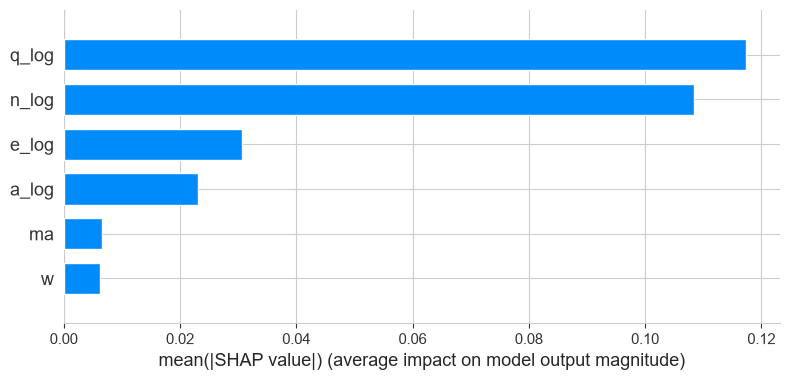

In [14]:
shap.summary_plot(shap_values_reg, X_sample, 
                  feature_names=X.columns.tolist(), 
                  plot_type='bar')

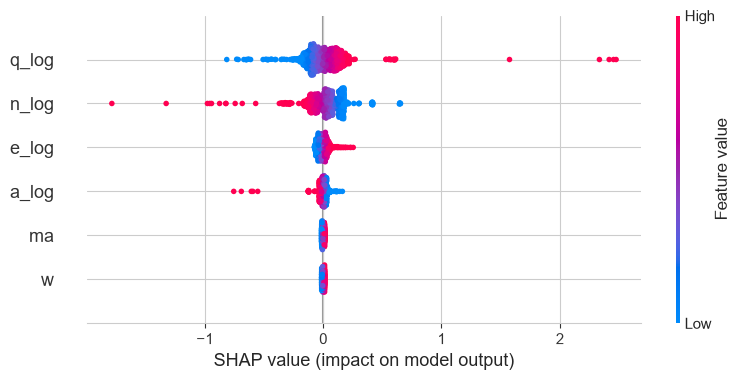

In [15]:
shap.summary_plot(shap_values_reg, X_sample, 
                  feature_names=X.columns.tolist())

In [16]:
import pickle

with open('../models/shap_explainer_reg.pkl', 'wb') as f:
    pickle.dump(explainer_reg, f)

print("SHAP explainer saved")

SHAP explainer saved
